# Students Performance — 시험 점수 살펴보기

원본: StudentsPerformance.csv 실습.

> **쉬운 말**
> 학생 1000명의 표입니다. 배경(성별·점심 등)과 수학·읽기·쓰기 점수가 있습니다.
> **입문**은 점수만으로 math를 맞춥니다. **확장**은 boxplot·IQR·Label Encoding까지 넣습니다.


## 1. 데이터 불러오기

`pd.read_csv`로 표를 엽니다. 경로의 `../data/`는 Jupyter 폴더 기준입니다.

In [21]:
# 표·그림·모델 도구
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score

# 학생 시험 성적 표 읽기 (1000행)
df = pd.read_csv("../data/StudentsPerformance.csv")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 2. EDA — 모양·타입·요약·결측

> **쉬운 말**  
> **shape** = 행·열 개수. **dtypes** = 칸마다 숫자인지 글자인지.  
> **describe** = 점수 칸의 평균·최소·최대 같은 요약.  
> **isna().sum()** = 비어 있는 칸이 몇 개인지(결측 확인).

In [22]:
# 행·열 개수와 칸 타입 확인
print("shape:", df.shape)
print(df.dtypes)
print("점수 요약:")
print(df.describe())

# 결측 개수 (0이면 빈 칸 없음)
print("결측 개수(칸별):")
print(df.isna().sum())


shape: (1000, 8)
gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object
점수 요약:
       math score  reading score  writing score
count  1000.00000    1000.000000    1000.000000
mean     66.08900      69.169000      68.054000
std      15.16308      14.600192      15.195657
min       0.00000      17.000000      10.000000
25%      57.00000      59.000000      57.750000
50%      66.00000      70.000000      69.000000
75%      77.00000      79.000000      79.000000
max     100.00000     100.000000     100.000000
결측 개수(칸별):
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score            

## 3. 점수 분포 — 히스토그램·boxplot

**히스토그램** = 점수가 어디에 많이 몰렸는지 막대로 봅니다.  
**boxplot** = 가운데·수염·튀는 점을 상자로 한눈에 봅니다.

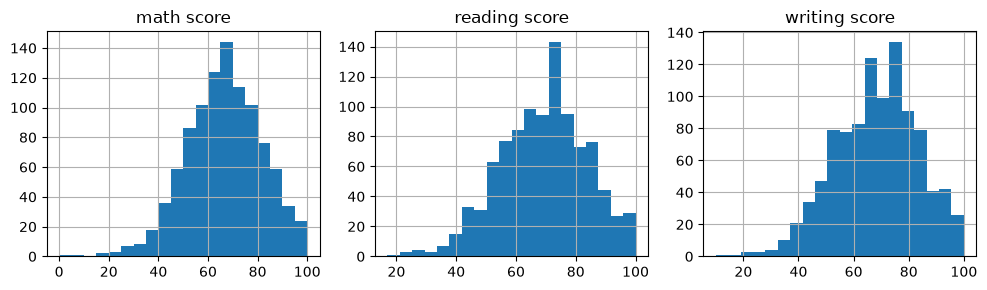

In [23]:
# 수학·읽기·쓰기 점수 분포(막대)
score_cols = ["math score", "reading score", "writing score"]
df[score_cols].hist(bins=20, figsize=(10, 3), layout=(1, 3))
plt.tight_layout()
plt.show()

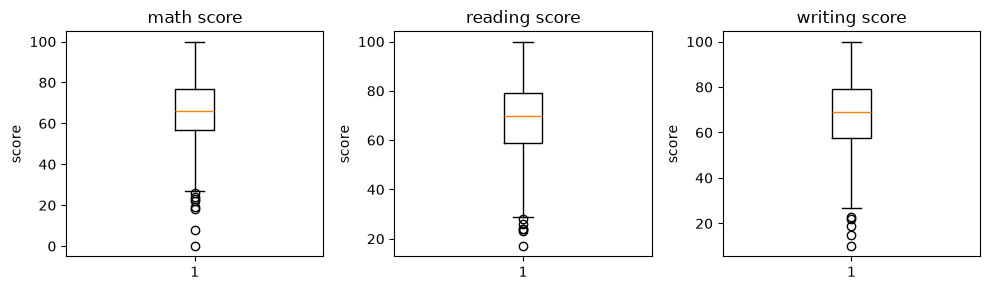

점수 boxplot 완료: ['math score', 'reading score', 'writing score']


In [24]:
# 같은 점수 칸을 상자 그림으로도 보기
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, col in zip(axes, score_cols):
    ax.boxplot(df[col])
    ax.set_title(col)
    ax.set_ylabel("score")
plt.tight_layout()
plt.show()
print("점수 boxplot 완료:", score_cols)


## 4. 범주형 칸 value_counts

> **쉬운 말**  
> 글자 칸은 종류별 **몇 명인지**만 세어 봅니다.  
> 모델에 넣으려면 나중에 숫자로 바꿔야 합니다(인코딩).

In [25]:
# 범주(글자) 칸별 개수
cat_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]
for col in cat_cols:
    print("===", col, "===")
    print(df[col].value_counts())
    print()

=== gender ===
gender
female    518
male      482
Name: count, dtype: int64

=== race/ethnicity ===
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

=== parental level of education ===
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

=== lunch ===
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

=== test preparation course ===
test preparation course
none         642
completed    358
Name: count, dtype: int64



## 5. 입문 — 점수만으로 math score 회귀

> **쉬운 말**
> 읽기·쓰기 점수로 수학 점수를 맞춥니다.
> **LinearRegression** = 직선(평면)으로 맞추는 가장 단순한 회귀.
> **MSE** = 틀린 정도(작을수록 좋음). **R²** = 1에 가까울수록 잘 맞춘 편.

입문은 범주 칸·IQR 없이 숫자 점수만 씁니다.


In [26]:
# 읽기·쓰기 → 수학 (입문, 점수만)
X = df[["reading score", "writing score"]]
y = df["math score"]

# 학습 80% / 시험 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("[입문] MSE:", mean_squared_error(y_test, y_pred))
print("[입문] R2:", r2_score(y_test, y_pred))


[입문] MSE: 77.24297821278957
[입문] R2: 0.6825697127424625


## 6. 확장 — IQR · Label Encoding · 다중선형

> **쉬운 말**
> **IQR** = 가운데 50% 폭. 폭의 1.5배 밖 점수는 튀는 값으로 보고 줄일 수 있습니다.
> **Label Encoding** = 글자(성별·점심 등)를 0, 1, 2… 번호로 바꿉니다.
> 그다음 범주 번호 + 읽기·쓰기로 다시 math를 맞추고 점수를 봅니다.


In [27]:
# IQR 1.5배 밖 행 제거
def filter_iqr(frame, cols, multiplier=1.5):
    """각 컬럼의 Q1±1.5*IQR 밖 행을 제거한 DataFrame 반환"""
    mask = pd.Series(True, index=frame.index)
    for col in cols:
        q1 = frame[col].quantile(0.25)
        q3 = frame[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - multiplier * iqr
        upper = q3 + multiplier * iqr
        mask &= frame[col].between(lower, upper)
    return frame.loc[mask].copy()

before = len(df)
df_iqr = filter_iqr(df, score_cols, multiplier=1.5)
after = len(df_iqr)

print(f"IQR 제거 전 행 수: {before}")
print(f"IQR 제거 후 행 수: {after}")
print(f"제거된 행 수: {before - after}")


IQR 제거 전 행 수: 1000
IQR 제거 후 행 수: 988
제거된 행 수: 12


In [28]:
# 글자 칸 → 번호 (확장 복사본)
df_enc = df_iqr.copy()
for col in cat_cols:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col])

print("인코딩 후 앞줄:")
df_enc[cat_cols + score_cols].head()


인코딩 후 앞줄:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,0,1,1,1,1,72,72,74
1,0,2,4,1,0,69,90,88
2,0,1,3,1,1,90,95,93
3,1,0,0,0,1,47,57,44
4,1,2,4,1,1,76,78,75


In [29]:
# 범주 번호 + 읽기·쓰기 → 수학 (확장)
feature_cols = cat_cols + ["reading score", "writing score"]
X2 = df_enc[feature_cols]
y2 = df_enc["math score"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
y2_pred = model2.predict(X2_test)

print("[확장] Feature:", feature_cols)
print("[확장] MSE:", mean_squared_error(y2_test, y2_pred))
print("[확장] R2:", r2_score(y2_test, y2_pred))


[확장] Feature: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'reading score', 'writing score']
[확장] MSE: 32.669218559321465
[확장] R2: 0.8506513959729273


## 한눈에

- 데이터: ../data/StudentsPerformance.csv (1000행)
- EDA: shape, dtypes, describe, 결측, hist, boxplot, value_counts
- **입문**: reading·writing → math (점수만), LinearRegression
- **확장**: 점수 IQR → 범주 Label Encoding → 다중선형
